**Chapter 7 : Time Series Regression Models**

In [1]:
library(fpp3)
library(tidyr)

Warning message:
"package 'fpp3' was built under R version 4.5.3"
── Attaching packages ──────────────────────────────────────────── fpp3 1.0.3 ──

✔ tibble      3.3.0     ✔ tsibble     1.2.0
✔ dplyr       1.1.4     ✔ tsibbledata 0.4.1
✔ tidyr       1.3.1     ✔ ggtime      1.0.0
✔ lubridate   1.9.4     ✔ feasts      0.5.0
✔ ggplot2     4.0.0     ✔ fable       0.5.0

Warning message:
"package 'tsibble' was built under R version 4.5.3"
Warning message:
"package 'tsibbledata' was built under R version 4.5.3"
Warning message:
"package 'ggtime' was built under R version 4.5.3"
Warning message:
"package 'feasts' was built under R version 4.5.3"
Warning message:
"package 'fabletools' was built under R version 4.5.3"
Warning message:
"package 'fable' was built under R version 4.5.3"
── Conflicts ───────────────────────────────────────────────── fpp3_conflicts ──
✖ lubridate::date()    masks base::date()
✖ dplyr::filter()      masks stats::filter()
✖ tsibble::intersect() masks base::intersect()

7.1 Half-hourly electricity demand for Victoria, Australia is contained in vic_elec. Extract the January 2014 electricity demand, and aggregate this data to daily with daily total demands and maximum temperatures.

In [4]:
# reduce dimension
head(vic_elec)
jan14_vic_elec <- vic_elec |>
  filter(yearmonth(Time) == yearmonth("2014 Jan")) |>
  index_by(Date = as_date(Time)) |>
  summarise(
    Demand = sum(Demand),
    Temperature = max(Temperature)
  )
head(jan14_vic_elec)

Time,Demand,Temperature,Date,Holiday
<dttm>,<dbl>,<dbl>,<date>,<lgl>
2012-01-01 00:00:00,4382.825,21.40,2012-01-01,TRUE
2012-01-01 00:30:00,4263.366,21.05,2012-01-01,TRUE
2012-01-01 01:00:00,4048.966,20.70,2012-01-01,TRUE
2012-01-01 01:30:00,3877.563,20.55,2012-01-01,TRUE
2012-01-01 02:00:00,4036.230,20.40,2012-01-01,TRUE
2012-01-01 02:30:00,3865.597,20.25,2012-01-01,TRUE


Date,Demand,Temperature
<date>,<dbl>,<dbl>
2014-01-01,175185.0,26.0
2014-01-02,188350.6,23.0
2014-01-03,189085.6,22.2
2014-01-04,173797.6,20.3
2014-01-05,169732.8,26.1
2014-01-06,195241.1,19.6


`geom_smooth()` using formula = 'y ~ x'


Series: Demand 
Model: TSLM 

Residuals:
     Min       1Q   Median       3Q      Max 
-49978.2 -10218.9   -121.3  18533.2  35440.6 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)  59083.9    17424.8   3.391  0.00203 ** 
Temperature   6154.3      601.3  10.235 3.89e-11 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 24540 on 29 degrees of freedom
Multiple R-squared: 0.7832,	Adjusted R-squared: 0.7757
F-statistic: 104.7 on 1 and 29 DF, p-value: 3.8897e-11


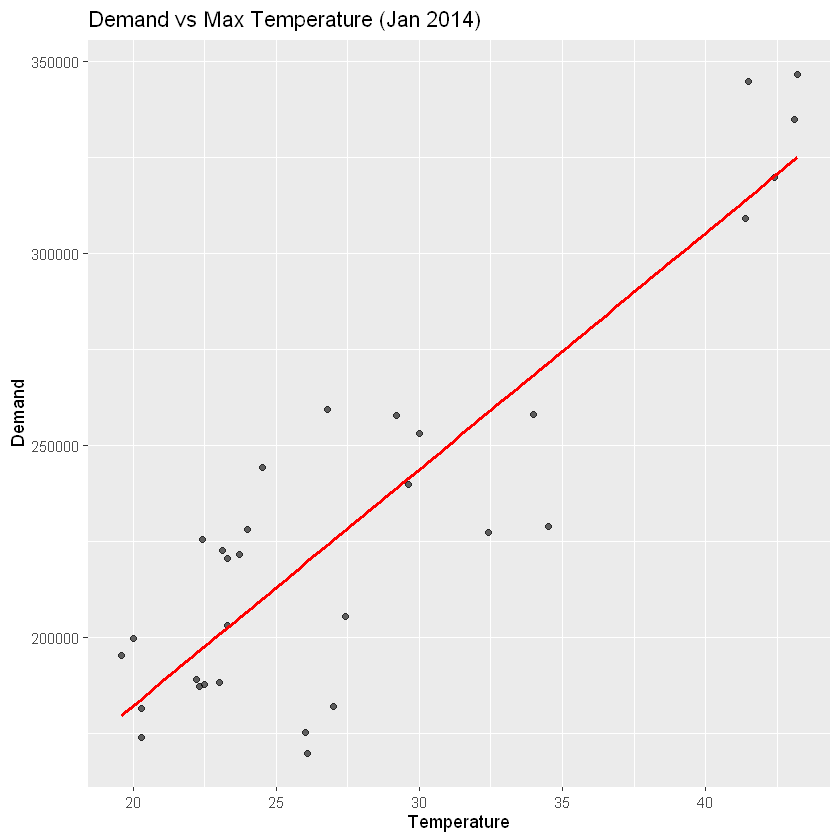

In [8]:
# a. Plot the data and find the regression model for
# Demand with temperature as a predictor variable.
# Why is there a positive relationship?
jan14_vic_elec |>
  ggplot(aes(x = Temperature, y = Demand)) +
  geom_point(alpha = 0.6) +
  geom_smooth(method = "lm", se = FALSE, color = "red") +
  labs(title = "Demand vs Max Temperature (Jan 2014)")

fit <- jan14_vic_elec |>
  model(TSLM(Demand ~ Temperature))

report(fit)

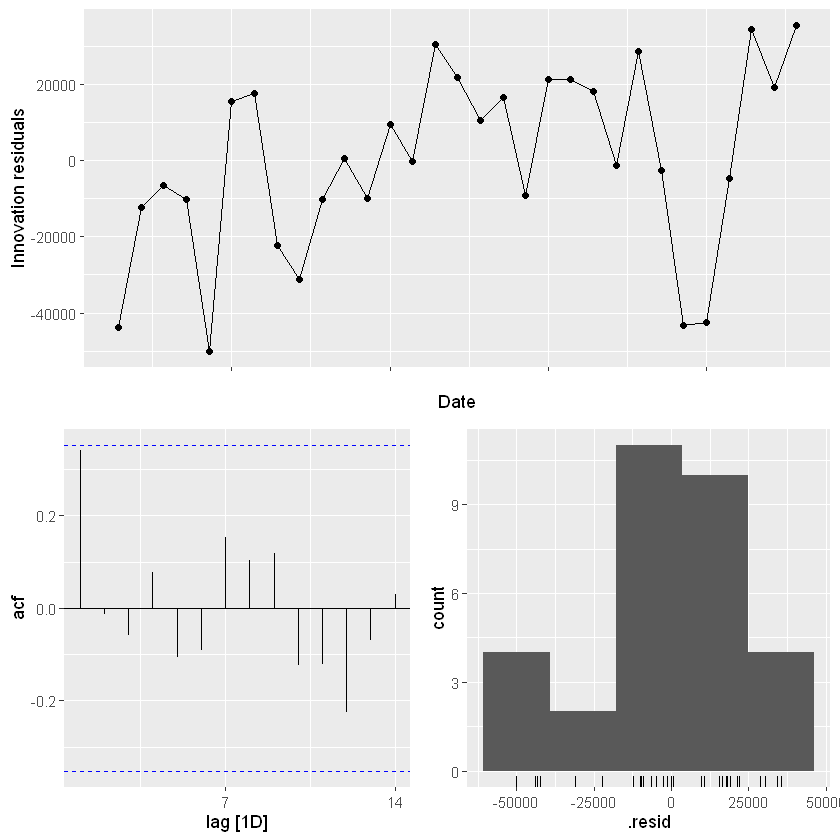

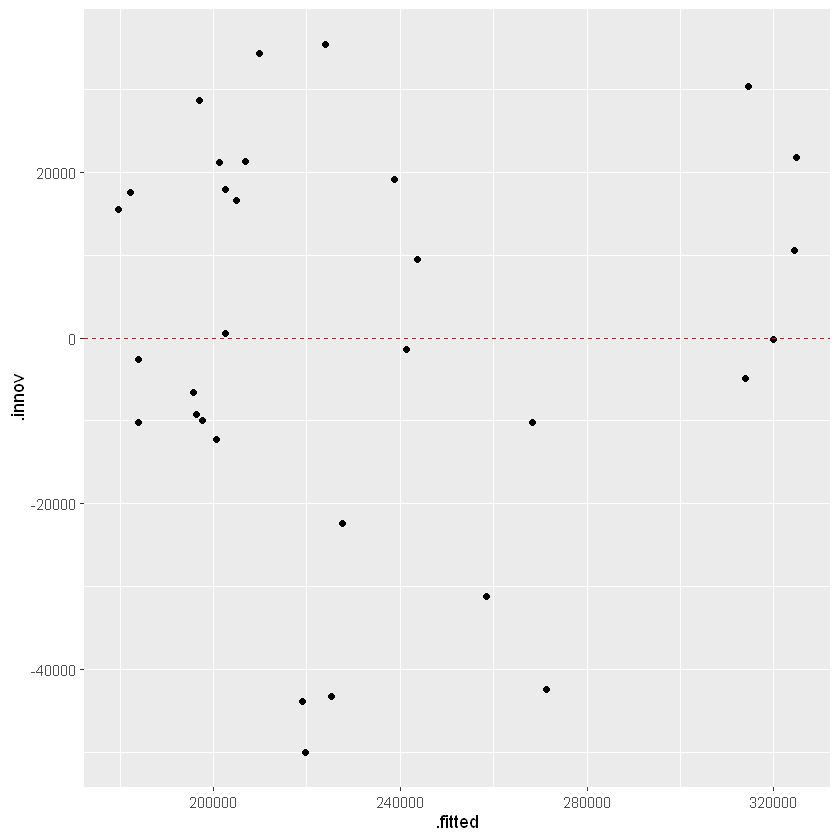

In [9]:
# b. Produce a residual plot.
# Is the model adequate? Are there any outliers or influential observations?
fit |> gg_tsresiduals()

fit |> augment() |>
  ggplot(aes(x = .fitted, y = .innov)) +
  geom_point() +
  geom_hline(yintercept = 0, linetype = "dashed", color = "red")

.mean
<dbl>
151398.4


.mean
<dbl>
274484.2


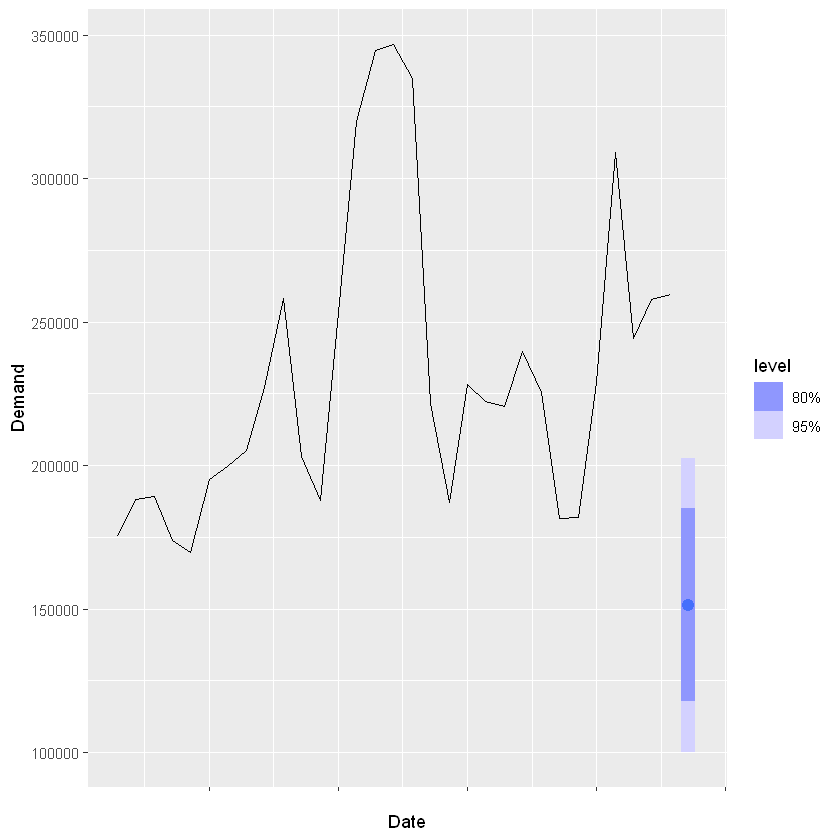

In [11]:
# c. Use the model to forecast the electricity demand that you would expect for
# the next day if the maximum temperature was 15∘C15∘C and compare it with the
# forecast if the with maximum temperature was 35∘C.
# Do you believe these forecasts? The following R code will get you started:
jan14_vic_elec |>
  model(TSLM(Demand ~ Temperature)) |>
  forecast(
    new_data(jan14_vic_elec, 1) |> mutate(Temperature = 15)
  ) |>
  autoplot(jan14_vic_elec)

fc_15 <- jan14_vic_elec |>
  model(TSLM(Demand ~ Temperature)) |>
  forecast(new_data(jan14_vic_elec, 1) |> mutate(Temperature = 15))

fc_35 <- jan14_vic_elec |>
  model(TSLM(Demand ~ Temperature)) |>
  forecast(new_data(jan14_vic_elec, 1) |> mutate(Temperature = 35))

fc_15 |> as_tibble() |> select(.mean)
fc_35 |> as_tibble() |> select(.mean)

In [12]:
# d. Give prediction intervals for your forecasts.
fc_15 |> hilo(level = c(80, 95))
fc_35 |> hilo(level = c(80, 95))


.model,Date,Demand,.mean,Temperature,80%,95%
<chr>,<date>,<dist>,<dbl>,<dbl>,<hilo>,<hilo>
TSLM(Demand ~ Temperature),2014-02-01,"N(151398, 6.8e+08)",151398.4,15,"[117908.1, 184888.6]80","[100179.4, 202617.3]95"


.model,Date,Demand,.mean,Temperature,80%,95%
<chr>,<date>,<dist>,<dbl>,<dbl>,<hilo>,<hilo>
TSLM(Demand ~ Temperature),2014-02-01,"N(274484, 6.4e+08)",274484.2,35,"[242088.4, 306880.1]80","[224939.1, 324029.4]95"


`geom_smooth()` using formula = 'y ~ x'


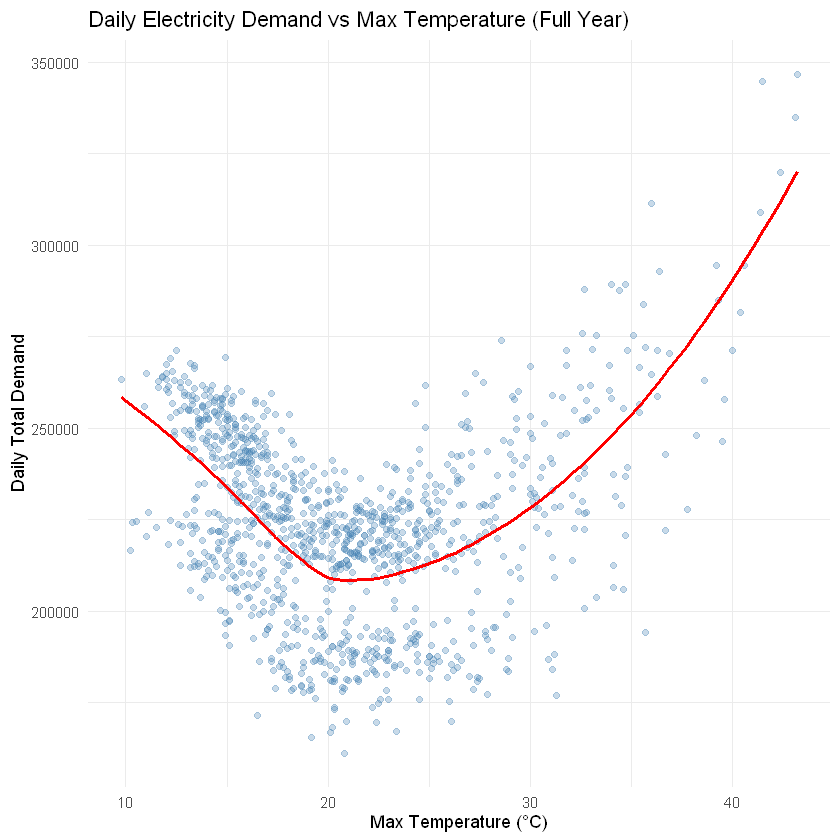

In [13]:
# e. Plot Demand vs Temperature for all of the available data in
# vic_elec aggregated to daily total demand and maximum temperature.
# What does this say about your model?
vic_elec_daily <-  vic_elec |>
  index_by(Date = as_date(Time)) |>
  summarise(
    Demand = sum(Demand),
    Temperature = max(Temperature)
  )

vic_elec_daily |>
  ggplot(aes(x = Temperature, y = Demand)) +
  geom_point(alpha = 0.3, color = "steelblue") +
  geom_smooth(method = "loess", color = "red", se = FALSE) + # 使用局部回归拟合曲线
  labs(
    title = "Daily Electricity Demand vs Max Temperature (Full Year)",
    x = "Max Temperature (°C)",
    y = "Daily Total Demand"
  ) +
  theme_minimal()

5.2

In [14]:
head(olympic_running)

Year,Length,Sex,Time
<int>,<int>,<chr>,<dbl>
1896,100,men,12.0
1900,100,men,11.0
1904,100,men,11.0
1908,100,men,10.8
1912,100,men,10.8
1916,100,men,NA


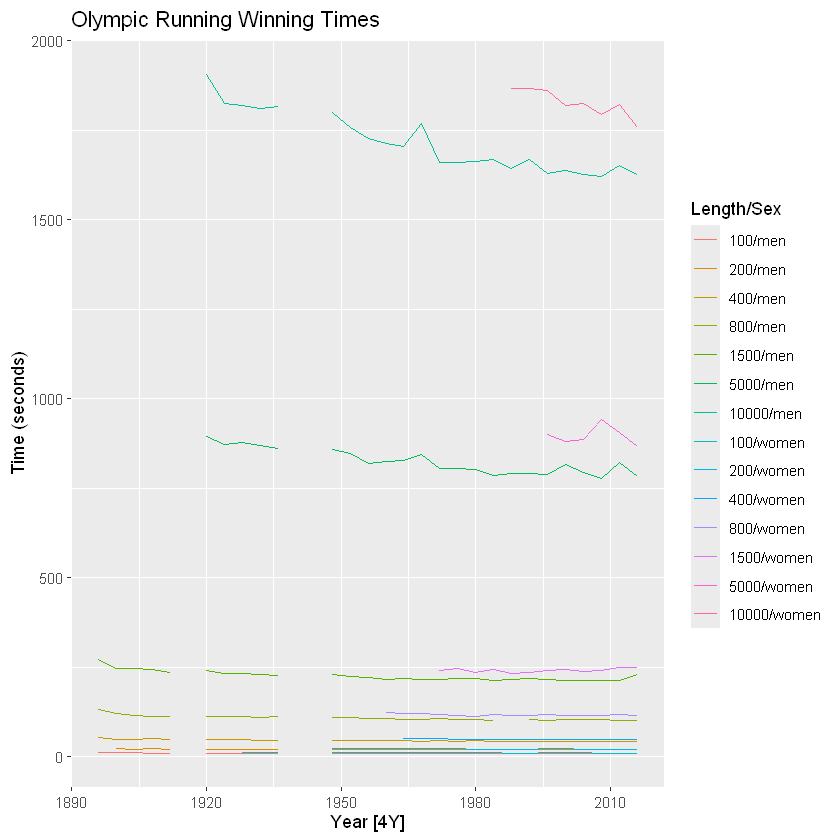

In [15]:
# a. Plot the winning time against the year for each event.
# Describe the main features of the plot.
olympic_running |>
  autoplot(Time) +
  labs(title = "Olympic Running Winning Times", y = "Time (seconds)")

In [16]:
# b. Fit a regression line to the data for each event.
# Obviously the winning times have been decreasing,
# but at what average rate per year?
fit <- olympic_running |>
  model(TSLM(Time ~ Year))

fit |> tidy()

Length,Sex,.model,term,estimate,std.error,statistic,p.value
<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
100,men,TSLM(Time ~ Year),(Intercept),35.01158063,2.347437e+00,14.9148102,2.944400e-14
100,men,TSLM(Time ~ Year),Year,-0.01261241,1.198424e-03,-10.5241677,7.240317e-11
100,women,TSLM(Time ~ Year),(Intercept),39.18816447,3.697686e+00,10.5980245,2.048455e-09
100,women,TSLM(Time ~ Year),Year,-0.01418503,1.872219e-03,-7.5765857,3.722557e-07
200,men,TSLM(Time ~ Year),(Intercept),69.37649842,3.553448e+00,19.5237112,1.193177e-16
200,men,TSLM(Time ~ Year),Year,-0.02488072,1.812007e-03,-13.7310319,3.795639e-13
200,women,TSLM(Time ~ Year),(Intercept),89.13761266,1.126772e+01,7.9108803,6.410968e-07
200,women,TSLM(Time ~ Year),Year,-0.03363261,5.684715e-03,-5.9163227,2.170598e-05
400,men,TSLM(Time ~ Year),(Intercept),172.48147736,1.148752e+01,15.0146815,2.518836e-14


In [18]:
check_data <- fit |> augment()
head(check_data)
colnames(check_data)

Length,Sex,.model,Year,Time,.fitted,.resid,.innov
<int>,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
100,men,TSLM(Time ~ Year),1896,12.0,11.09845,0.901553670,0.901553670
100,men,TSLM(Time ~ Year),1900,11.0,11.04800,-0.047996679,-0.047996679
100,men,TSLM(Time ~ Year),1904,11.0,10.99755,0.002452971,0.002452971
100,men,TSLM(Time ~ Year),1908,10.8,10.94710,-0.147097379,-0.147097379
100,men,TSLM(Time ~ Year),1912,10.8,10.89665,-0.096647728,-0.096647728
100,men,TSLM(Time ~ Year),1916,NA,NA,NA,NA


[1] "Length"  "Sex"     ".model"  "Year"    "Time"    ".fitted" ".resid" 
[8] ".innov"

Warning message:
"Removed 31 rows containing missing values or values outside the scale range
(`geom_point()`)."


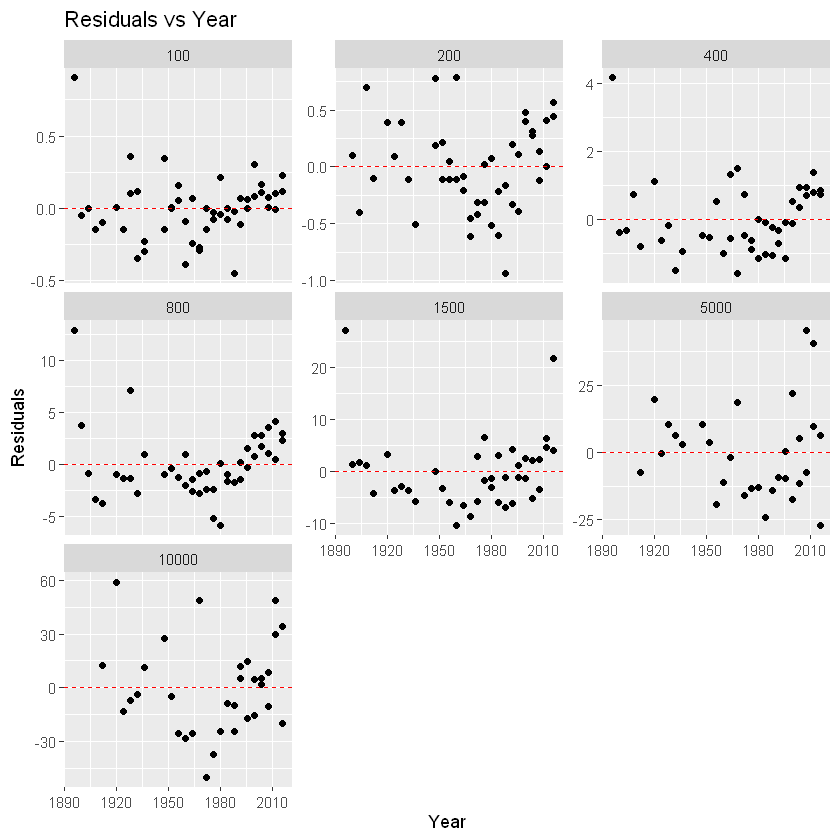

In [19]:
# c. Plot the residuals against the year.
# What does this indicate about the suitability of the fitted lines?
fit |> augment() |>
  ggplot(aes(x = Year, y = .resid)) +
  geom_point() +
  geom_hline(yintercept = 0, color = "red", linetype = "dashed") +
  facet_wrap(~ Length, scales = "free_y") +
  labs(title = "Residuals vs Year", y = "Residuals")

In [21]:
# d. Predict the winning time for each race in the 2020 Olympics.
# Give a prediction interval for your forecasts.
# What assumptions have you made in these calculations?
fc_2020 <- fit |>
  forecast(new_data = new_data(olympic_running, 1) |> mutate(Year == 2020))

fc_2020 |> hilo(level = 95)

Length,Sex,.model,Year,Time,.mean,Year == 2020,95%
<int>,<chr>,<chr>,<dbl>,<dist>,<dbl>,<lgl>,<hilo>
100,men,TSLM(Time ~ Year),2020,"N(9.5, 0.061)",9.534507,TRUE,"[ 9.049446, 10.01957]95"
100,women,TSLM(Time ~ Year),2020,"N(11, 0.059)",10.534409,TRUE,"[ 10.056992, 11.01183]95"
200,men,TSLM(Time ~ Year),2020,"N(19, 0.13)",19.117439,TRUE,"[ 18.423087, 19.81179]95"
200,women,TSLM(Time ~ Year),2020,"N(21, 0.31)",21.199739,TRUE,"[ 20.106551, 22.29293]95"
400,men,TSLM(Time ~ Year),2020,"N(42, 1.5)",42.042310,TRUE,"[ 39.668596, 44.41603]95"
400,women,TSLM(Time ~ Year),2020,"N(48, 1.4)",48.436264,TRUE,"[ 46.123295, 50.74923]95"
800,men,TSLM(Time ~ Year),2020,"N(99, 13)",99.237699,TRUE,"[ 92.137378, 106.33802]95"
800,women,TSLM(Time ~ Year),2020,"N(111, 14)",111.483433,TRUE,"[ 104.105124, 118.86174]95"
1500,men,TSLM(Time ~ Year),2020,"N(207, 74)",206.998282,TRUE,"[ 190.091940, 223.90462]95"


5.4

Month,Sales
<mth>,<dbl>
1987 1月,1664.81
1987 2月,2397.53
1987 3月,2840.71
1987 4月,3547.29
1987 5月,3752.96
1987 6月,3714.74


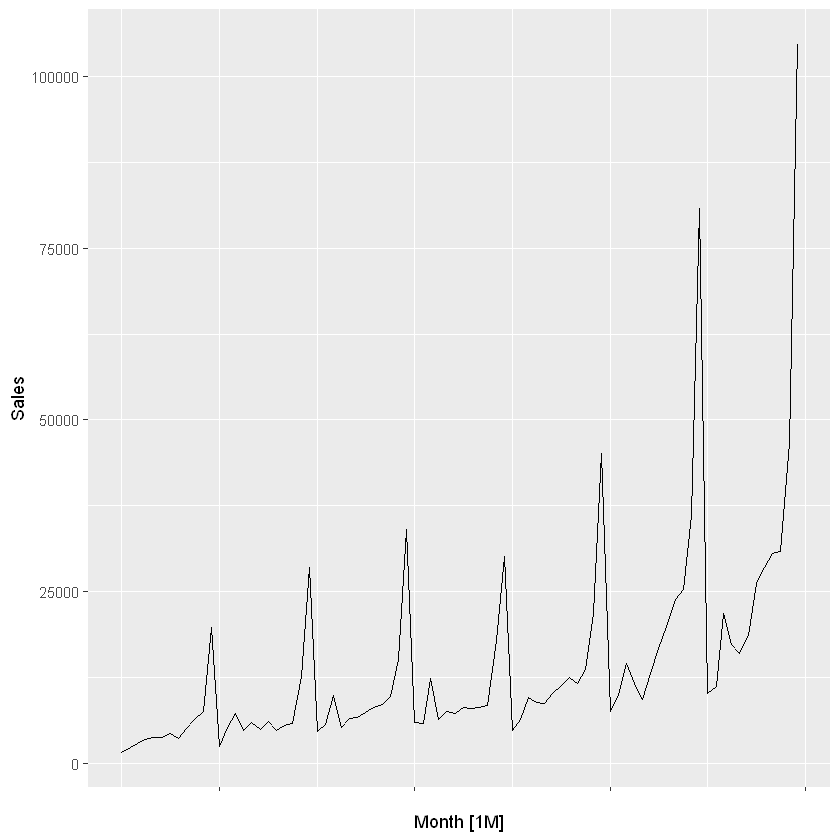

In [22]:
# a. a time plot of the data and describe the patterns in the graph
# Identify any unusual or unexpected fluctuations in the time series
head(souvenirs)
souvenirs |> autoplot(Sales)

In [24]:
# c. Fit a regression model to the logarithms of these sales data
# with a linear trend, # seasonal dummies and a “surfing festival”
# dummy variable.
souv_data <- souvenirs |>
  mutate(
    Surfing_Festival = if_else(month(Month) == 3 & year(Month) >= 1988, 1, 0)
  )

fit <- souv_data |>
  model(
    TSLM(log(Sales) ~ trend() + season() + Surfing_Festival)
  )

report(fit)

Series: Sales 
Model: TSLM 
Transformation: log(Sales) 

Residuals:
      Min        1Q    Median        3Q       Max 
-0.336727 -0.127571  0.002568  0.109106  0.376714 

Coefficients:
                  Estimate Std. Error t value Pr(>|t|)    
(Intercept)      7.6196670  0.0742471 102.626  < 2e-16 ***
trend()          0.0220198  0.0008268  26.634  < 2e-16 ***
season()year2    0.2514168  0.0956790   2.628 0.010555 *  
season()year3    0.2660828  0.1934044   1.376 0.173275    
season()year4    0.3840535  0.0957075   4.013 0.000148 ***
season()year5    0.4094870  0.0957325   4.277 5.88e-05 ***
season()year6    0.4488283  0.0957647   4.687 1.33e-05 ***
season()year7    0.6104545  0.0958039   6.372 1.71e-08 ***
season()year8    0.5879644  0.0958503   6.134 4.53e-08 ***
season()year9    0.6693299  0.0959037   6.979 1.36e-09 ***
season()year10   0.7473919  0.0959643   7.788 4.48e-11 ***
season()year11   1.2067479  0.0960319  12.566  < 2e-16 ***
season()year12   1.9622412  0.0961066  20.417  <

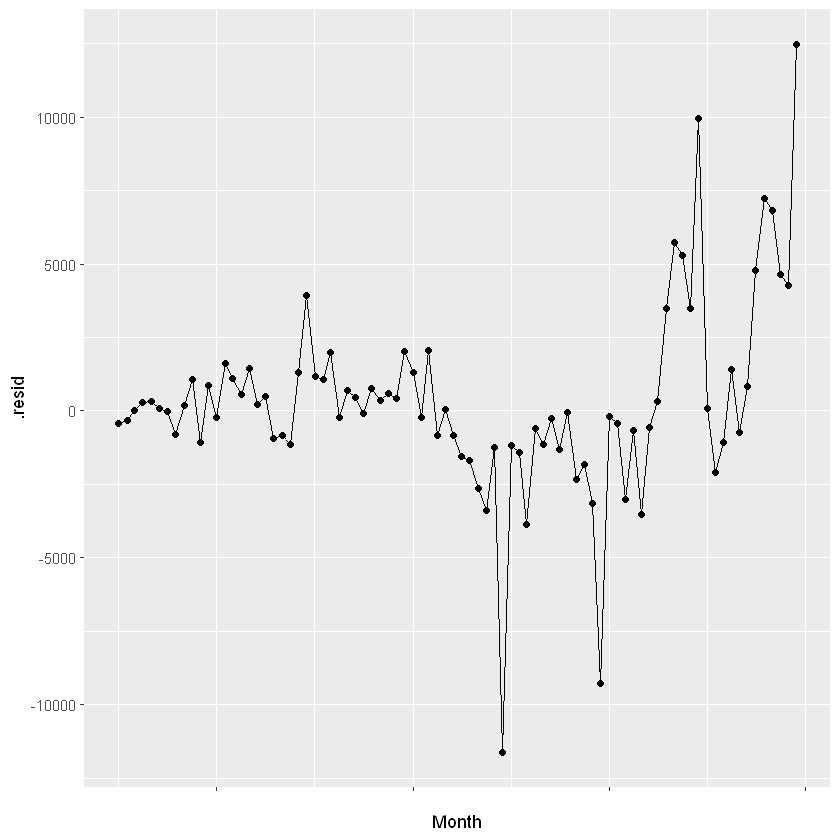

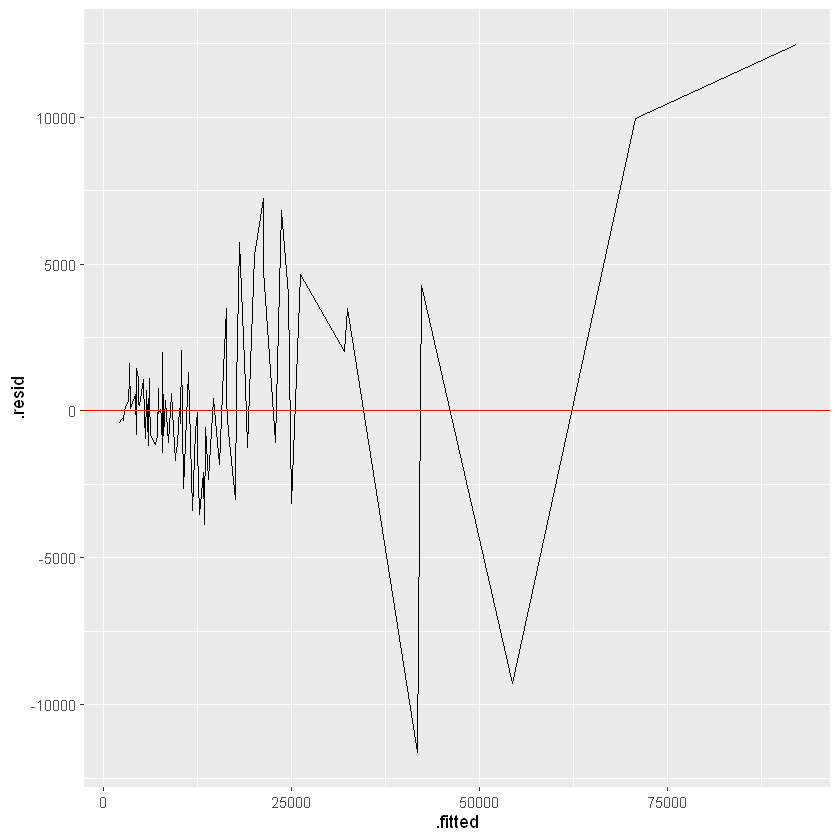

In [26]:
# d. Plot the residuals against time and against the fitted values.
# Do these plots reveal any problems with the model?
fit |> augment() |>
  ggplot(aes(x = Month, y = .resid)) +
  geom_line() +
  geom_point()

fit |> augment() |>
  ggplot(aes(x = .fitted, y = .resid)) +
  geom_line() +
  geom_hline(yintercept = 0, color = "red")

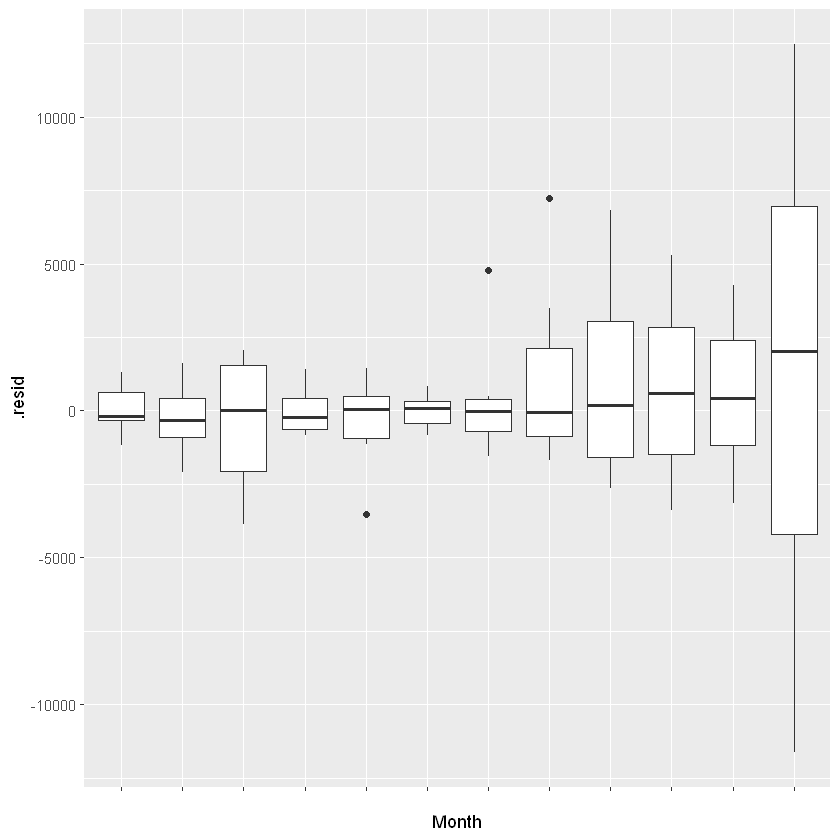

In [28]:
# e. Do boxplots of the residuals for each month.
# Does this reveal any problems with the model?
fit |> augment() |>
  ggplot(aes(x = factor(month(Month, label = TRUE)), y = .resid)) +
  geom_boxplot() +
  labs(x = "Month")

In [30]:
# g. What does the Ljung-Box test tell you about your model?
fit |> augment() |> features(.innov, ljung_box, lag = 24)

.model,lb_stat,lb_pvalue
<chr>,<dbl>,<dbl>
TSLM(log(Sales) ~ trend() + season() + Surfing_Festival),112.3923,2.149392e-13


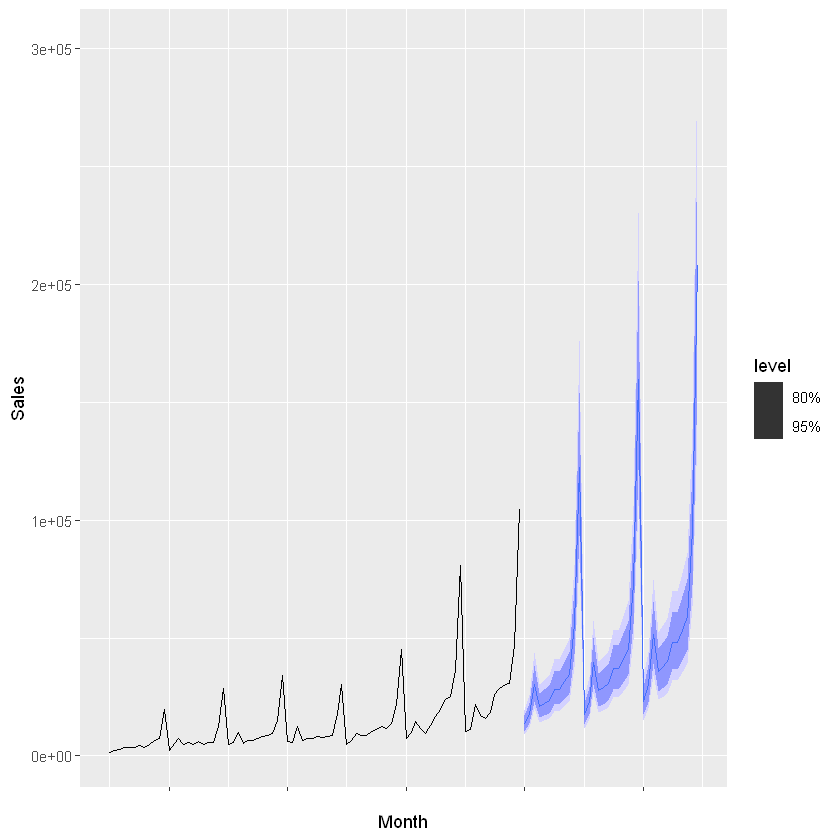

In [31]:
# Regardless of your answers to the above questions,
# use your regression model to predict the monthly sales 
# for 1994, 1995, and 1996.
# Produce prediction intervals for each of your forecasts.
new_souv <- new_data(souv_data, 36) |> 
  mutate(
    Surfing_Festival = if_else(month(Month) == 3, 1, 0)
  )


fc <- fit |> forecast(new_data = new_souv)

fc |> autoplot(souv_data)

5.5

In [43]:
head(us_gasoline)
gas_2004 <- us_gasoline |>
  filter(year(Week) <= 2004)

Week,Barrels
<week>,<dbl>
1991 W06,6.621
1991 W07,6.433
1991 W08,6.582
1991 W09,7.224
1991 W10,6.875
1991 W11,6.947


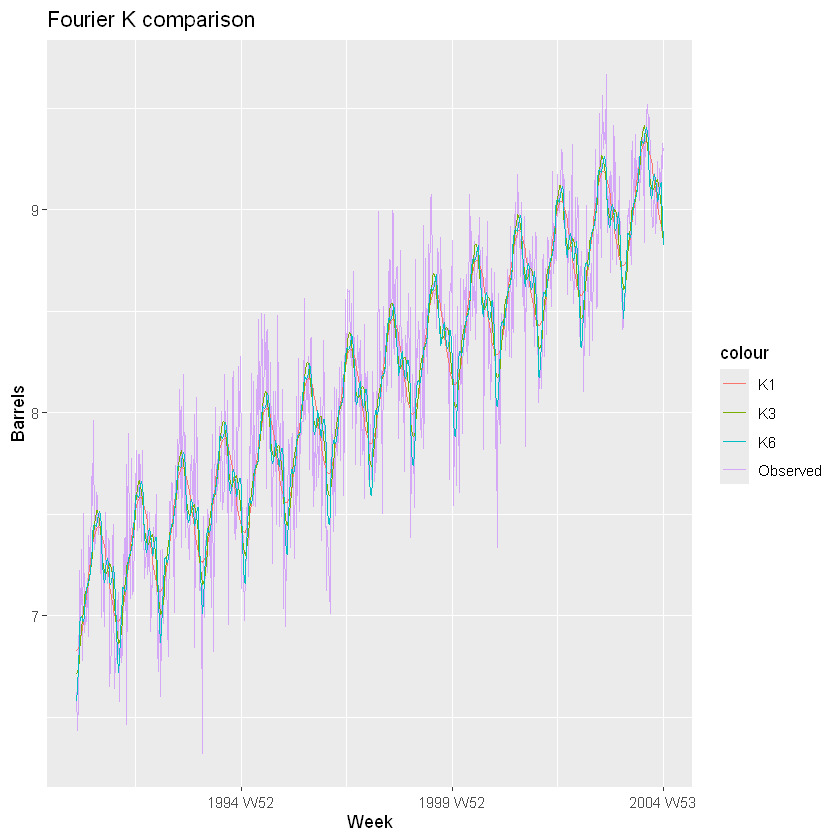

In [37]:
# a. Fit a harmonic regression with trend to the data.
# Experiment with changing the number Fourier terms.
# Plot the observed gasoline and fitted values and comment on what you see.
fit_a <- gas_2004 |>
  model(
    K1 = TSLM(Barrels ~ trend() + fourier(K = 1)),
    K3 = TSLM(Barrels ~ trend() + fourier(K = 3)),
    K6 = TSLM(Barrels ~ trend() + fourier(K = 6))
  )

fit_a |>
  augment() |>
  ggplot(aes(x = Week)) +
  geom_line(aes(y = Barrels, color = "Observed"), alpha = 0.6) +
  geom_line(aes(y = .fitted, color = .model)) +
  labs(title = "Fourier K comparison", y = "Barrels")

In [45]:
library(purrr)

In [52]:
# Select the appropriate number of Fourier terms to include
# by minimising the AICc or CV value.
fit_b <- map(1:20, function(k) {
  gas_2004 |>
    model(TSLM(Barrels ~ trend() + fourier(K = k))) |>
    glance() |>
    mutate(.model = paste0("K", k))
}) |>
  bind_rows()

fit_b |>
  arrange(AICc) |>
  select(.model, AICc)

.model,AICc
<chr>,<dbl>
K7,-1887.354
K11,-1884.716
K8,-1884.573
K12,-1884.433
K6,-1883.542
K9,-1881.947
K10,-1881.415
K13,-1881.347
K14,-1878.761


.model,lb_stat,lb_pvalue
<chr>,<dbl>,<dbl>
TSLM(Barrels ~ trend() + fourier(K = 7)),56.8572,0.2990426


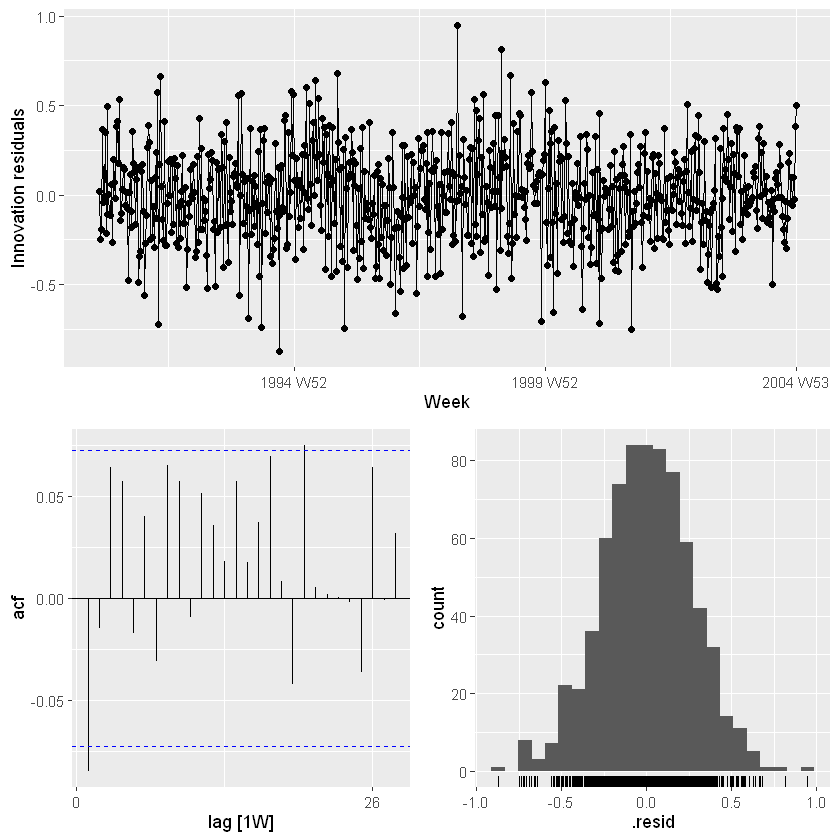

In [54]:
# c. Plot the residuals of the final model using the gg_tsresiduals() function
# and comment on these. Use a Ljung-Box test to check for
# residual autocorrelation.
best_fit <- gas_2004 |>
  model(TSLM(Barrels ~ trend() + fourier(K = 7)))

best_fit |> gg_tsresiduals()

best_fit |> augment() |> features(.innov, ljung_box, lag = 52)

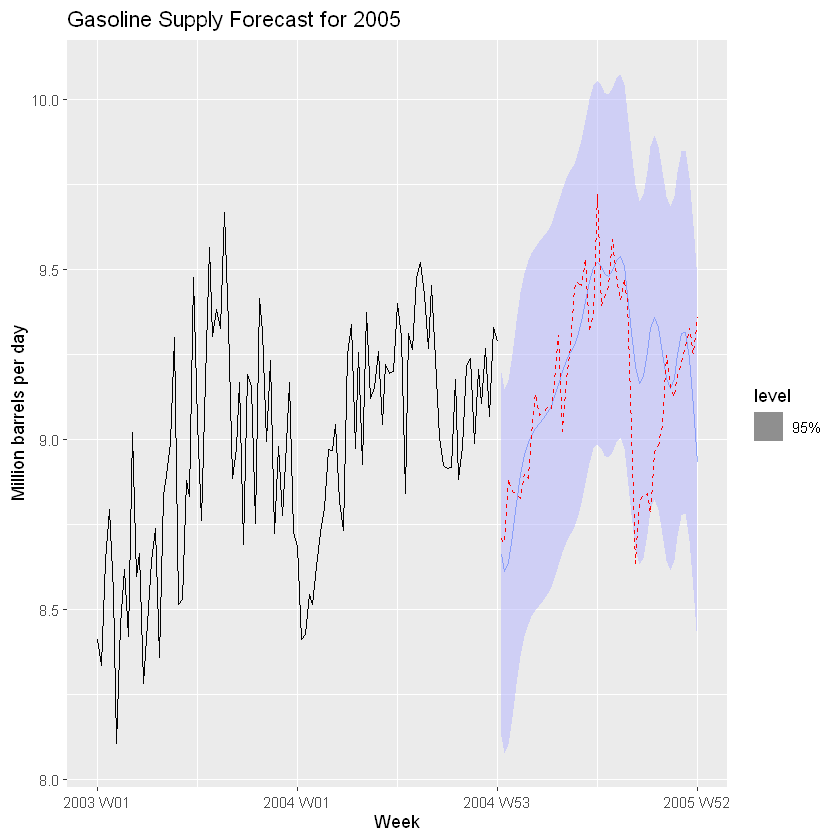

In [55]:
# d. Generate forecasts for the next year of data and plot these
# along with the actual data for 2005. Comment on the forecasts.
fc <- best_fit |> forecast(h = 52)

gas_2005_actual <- us_gasoline |> filter(year(Week) == 2005)

gas_2004 |>
  filter(year(Week) >= 2003) |>
  autoplot(Barrels) +
  autolayer(fc, Barrels, level = 95, alpha = 0.5) +
  autolayer(gas_2005_actual, Barrels, color = "red", linetype = "dashed") +
  labs(
    title = "Gasoline Supply Forecast for 2005",
    y = "Million barrels per day",
    x = "Week"
  )

5.6 annual population of Afghanistan 

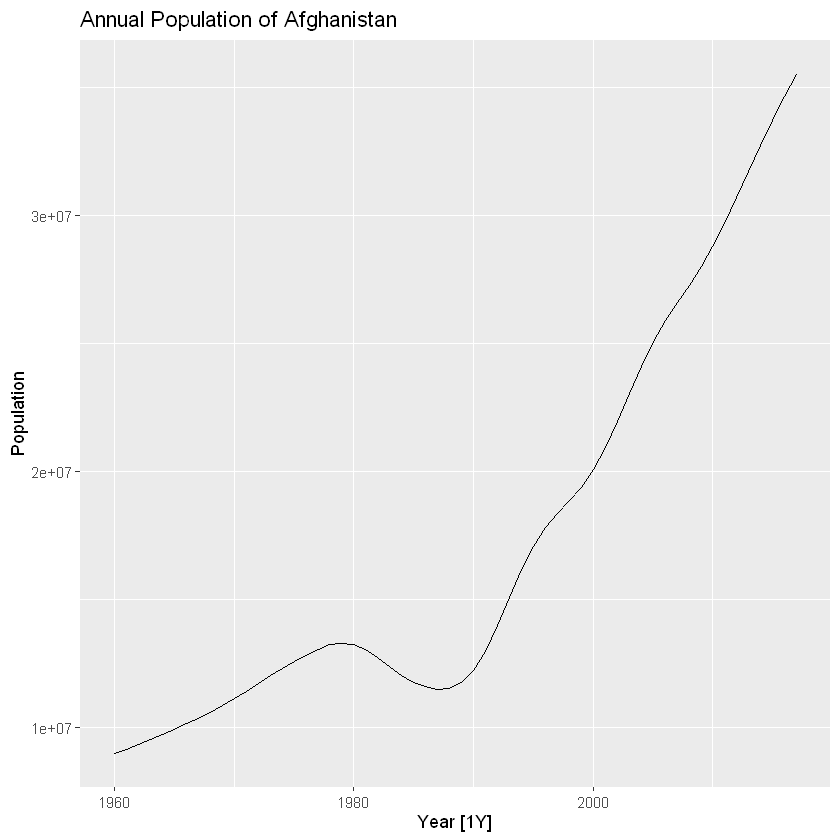

In [56]:
# a. Plot the data and comment on its features
afghan <- global_economy |>
  filter(Country == "Afghanistan") |>
  select(Year, Population)

afghan |>
  autoplot(Population) +
  labs(title = "Annual Population of Afghanistan", y = "Population")

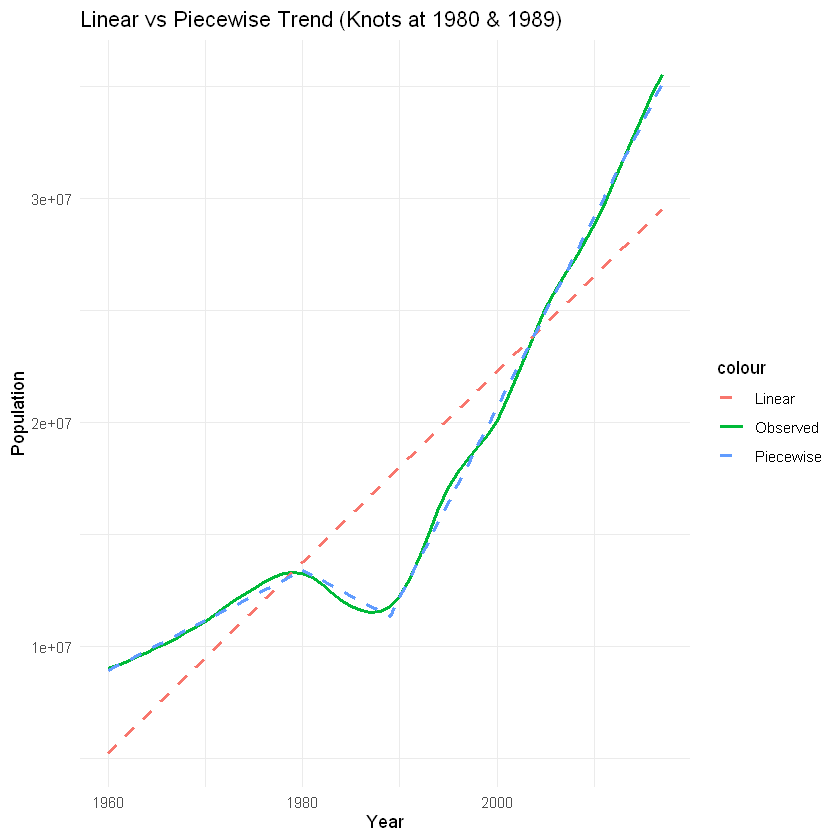

In [58]:
# b. Fit a linear trend model and
# compare this to a piecewise linear trend model with knots at 1980 and 1989.
fit_models <- afghan |>
  model(
    Linear = TSLM(Population ~ trend()),
    Piecewise = TSLM(Population ~ trend(knots = c(1980, 1989)))
  )

fit_models |>
  augment() |>
  ggplot(aes(x = Year)) +
  geom_line(aes(y = Population, color = "Observed"), size = 1) +
  geom_line(aes(y = .fitted, color = .model), linewidth = 1, linetype = "dashed") +
  labs(title = "Linear vs Piecewise Trend (Knots at 1980 & 1989)", y = "Population") +
  theme_minimal()

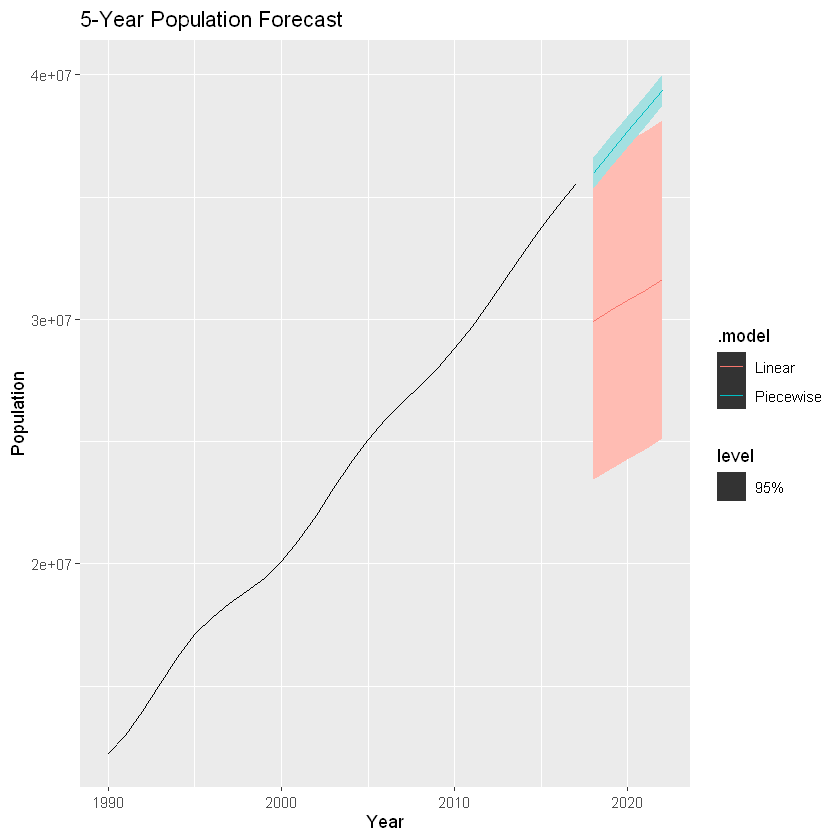

In [59]:
# Generate forecasts from these two models for the five years after
# the end of the data, and comment on the results.
fc <- fit_models |> forecast(h = 5)

fc |>
  autoplot(afghan |> filter(Year >= 1990), level = 95) + # 只看后半段历史，方便对比
  labs(title = "5-Year Population Forecast", y = "Population")